In [5]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("emiliovenegas1/mammography-dataset-from-inbreast-mias-and-ddsm")

print("Path to dataset files:", path)

100%|██████████| 593M/593M [00:09<00:00, 68.4MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/emiliovenegas1/mammography-dataset-from-inbreast-mias-and-ddsm/versions/1


In [6]:
import pandas as pd
import numpy as np
import os

# The dataset was downloaded using kagglehub in the previous cell
kagglehub_path = "/root/.cache/kagglehub/datasets/emiliovenegas1/mammography-dataset-from-inbreast-mias-and-ddsm/versions/1"

# Set the path to CLAHE_images in the downloaded folder
base_path = os.path.join(kagglehub_path, "CLAHE_images")

categories = ["benign", "malignant", "normal"]
image_paths = []
labels = []

if os.path.exists(base_path):
    for category in categories:
        category_path = os.path.join(base_path, category)
        if os.path.exists(category_path):
            for image_name in os.listdir(category_path):
                image_path = os.path.join(category_path, image_name)
                image_paths.append(image_path)
                labels.append(category)

    df = pd.DataFrame({
        "image_path": image_paths,
        "label": labels
    })
    print(f"Success! Total images loaded: {len(df)}")
    display(df.head())
else:
    print(f"Could not find dataset directory at: {base_path}")

Success! Total images loaded: 26602


,image_path,label
0,/root/.cache/kagglehub/datasets/emiliovenegas1...,benign
1,/root/.cache/kagglehub/datasets/emiliovenegas1...,benign
2,/root/.cache/kagglehub/datasets/emiliovenegas1...,benign
3,/root/.cache/kagglehub/datasets/emiliovenegas1...,benign
4,/root/.cache/kagglehub/datasets/emiliovenegas1...,benign


In [7]:
df.tail()

,image_path,label
26597,/root/.cache/kagglehub/datasets/emiliovenegas1...,normal
26598,/root/.cache/kagglehub/datasets/emiliovenegas1...,normal
26599,/root/.cache/kagglehub/datasets/emiliovenegas1...,normal
26600,/root/.cache/kagglehub/datasets/emiliovenegas1...,normal
26601,/root/.cache/kagglehub/datasets/emiliovenegas1...,normal


In [12]:
df.shape

(26602, 2)

In [13]:
df.columns

Index(['image_path', 'label'], dtype='object')

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.isnull().sum()

,0
image_path,0
label,0


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26602 entries, 0 to 26601
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   image_path  26602 non-null  object
 1   label       26602 non-null  object
dtypes: object(2)
memory usage: 415.8+ KB


In [17]:
df['label'].unique()

array(['benign', 'malignant', 'normal'], dtype=object)

In [18]:
df['label'].value_counts()

,count
label,
malignant,13710
benign,10866
normal,2026


/tmp/ipykernel_666/568700443.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="label", palette="viridis", ax=ax)


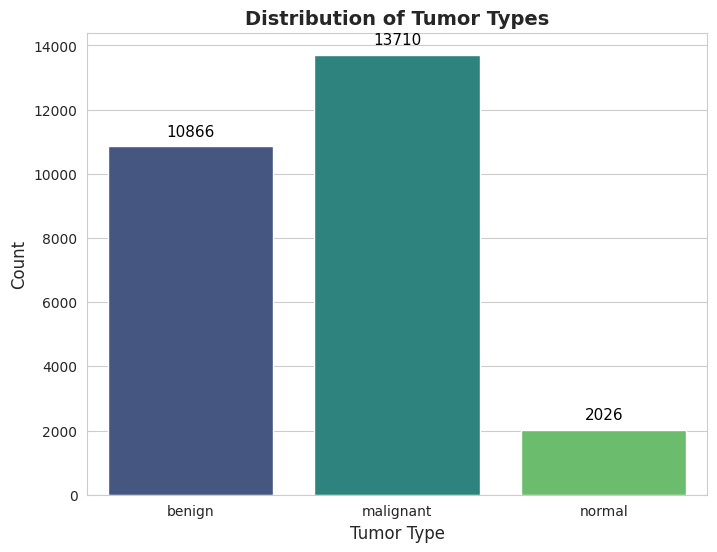

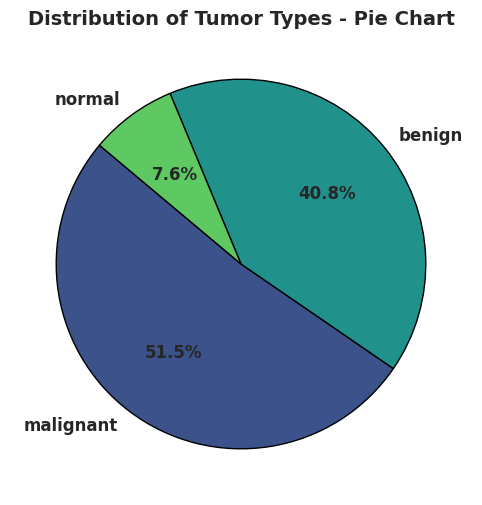

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")

fig, ax = plt.subplots(figsize=(8, 6))
sns.countplot(data=df, x="label", palette="viridis", ax=ax)

ax.set_title("Distribution of Tumor Types", fontsize=14, fontweight='bold')
ax.set_xlabel("Tumor Type", fontsize=12)
ax.set_ylabel("Count", fontsize=12)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11, color='black',
                xytext=(0, 5), textcoords='offset points')

plt.show()

label_counts = df["label"].value_counts()

fig, ax = plt.subplots(figsize=(8, 6))
colors = sns.color_palette("viridis", len(label_counts))

ax.pie(label_counts, labels=label_counts.index, autopct='%1.1f%%',
       startangle=140, colors=colors, textprops={'fontsize': 12, 'weight':
'bold'},
       wedgeprops={'edgecolor': 'black', 'linewidth': 1})

ax.set_title("Distribution of Tumor Types - Pie Chart", fontsize=14,
fontweight='bold')

plt.show()

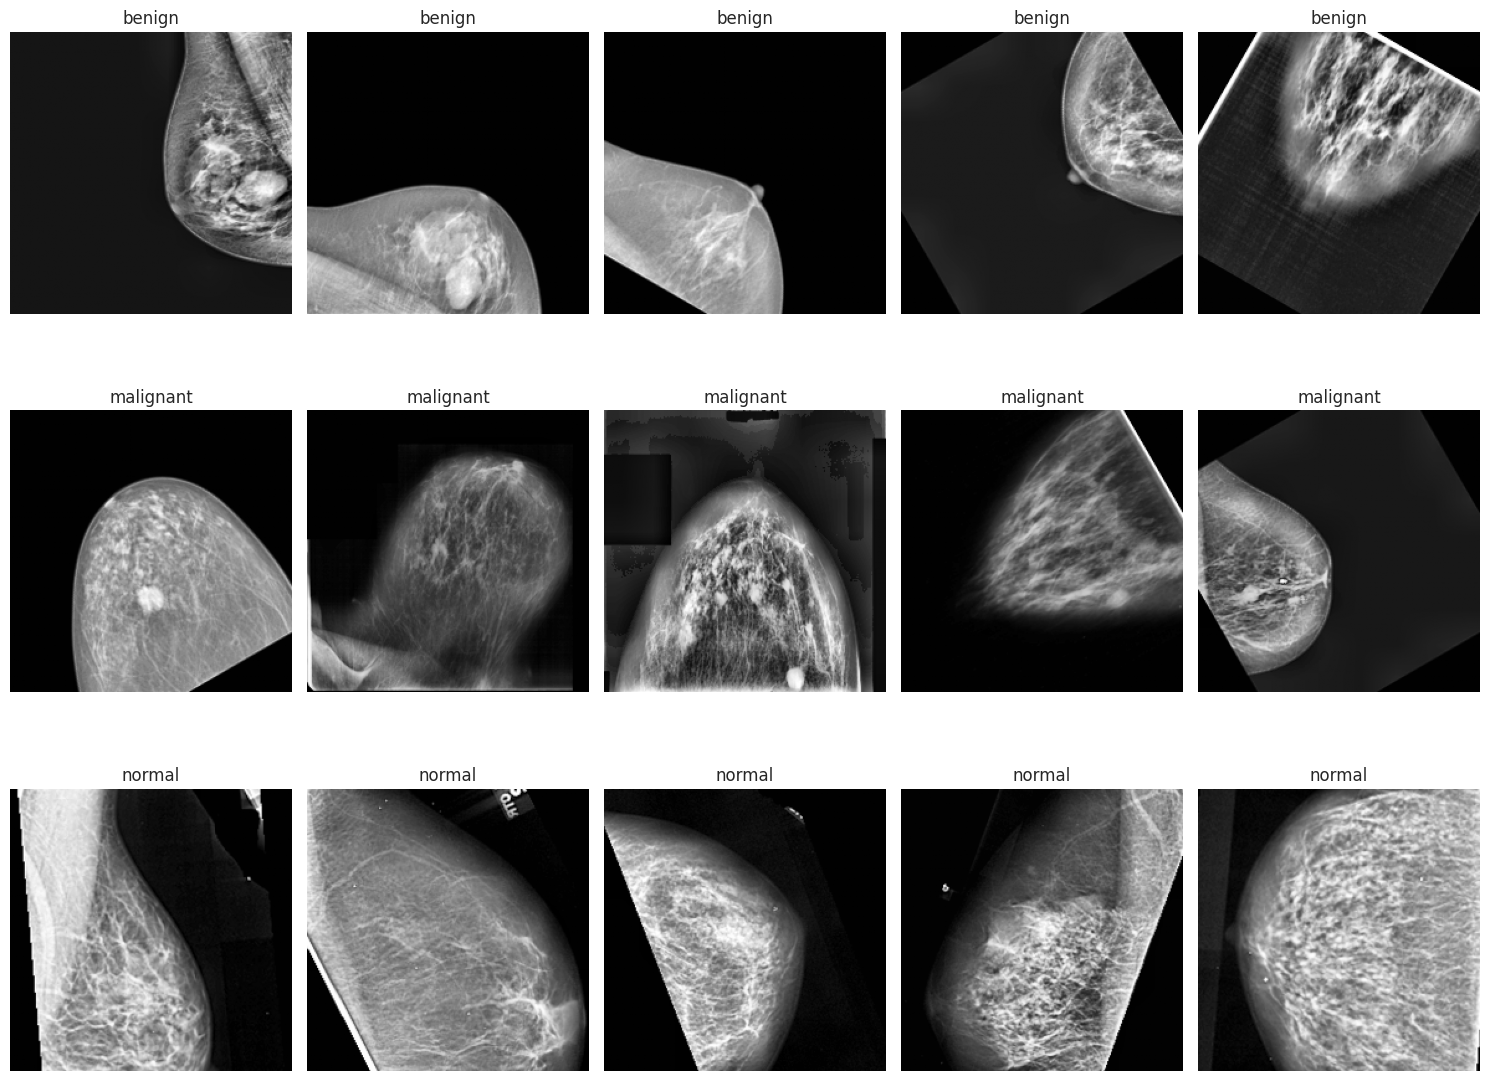

In [20]:
import cv2
import matplotlib.pyplot as plt

num_images = 5
plt.figure(figsize=(15, 12))

for i, category in enumerate(categories):
    category_images = df[df['label'] == category]['image_path'].iloc[:num_images]
    for j, img_path in enumerate(category_images):
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        plt.subplot(len(categories), num_images, i * num_images + j + 1)
        plt.imshow(img, cmap='gray')
        plt.axis('off')
        plt.title(category)

plt.tight_layout()
plt.show()

In [21]:
import os, random, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
from sklearn.metrics import (
classification_report, confusion_matrix,
roc_auc_score, roc_curve, auc,
accuracy_score, f1_score, precision_score,
recall_score, cohen_kappa_score
)
from sklearn.preprocessing import label_binarize
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {DEVICE}')
print(f'PyTorch: {torch.__version__}')

Device : cuda
PyTorch: 2.14.1+cu130


In [22]:
LABEL2IDX = {'benign': 0, 'malignant': 1, 'normal': 2}
IDX2LABEL = {v: k for k, v in LABEL2IDX.items()}
CLASS_NAMES = list(LABEL2IDX.keys())
NUM_CLASSES = 3

df['label_idx'] = df['label'].map(LABEL2IDX)
# ── Step 1: Stratified 70 / 15 / 15 split ─────────────────────────────────
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df['label_idx'], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df['label_idx'], random_state=SEED
)

print('Before oversampling:')
print(f'  Train : {len(train_df):>6}  {dict(train_df["label"].value_counts())}')
print(f'  Val   : {len(val_df):>6}  {dict(val_df["label"].value_counts())}')
print(f'  Test  : {len(test_df):>6}  {dict(test_df["label"].value_counts())}')

Before oversampling:
  Train :  18621  {'malignant': np.int64(9597), 'benign': np.int64(7606), 'normal': np.int64(1418)}
  Val   :   3990  {'malignant': np.int64(2056), 'benign': np.int64(1630), 'normal': np.int64(304)}
  Test  :   3991  {'malignant': np.int64(2057), 'benign': np.int64(1630), 'normal': np.int64(304)}


In [23]:
# ── Step 2: Oversample minority classes in TRAIN only ─────────────────────
max_count = train_df['label'].value_counts().max()

oversampled_parts = []
for cls in CLASS_NAMES:
    cls_df = train_df[train_df['label'] == cls]
    if len(cls_df) < max_count:
        cls_df = resample(
            cls_df,
            replace=True,
            n_samples=max_count,
            random_state=SEED
        )
    oversampled_parts.append(cls_df)

train_df_balanced = (
    pd.concat(oversampled_parts)
      .sample(frac=1, random_state=SEED)   # shuffle
      .reset_index(drop=True)
)

print('After oversampling (train only):')
print(f'  Train : {len(train_df_balanced):>6}  {dict(train_df_balanced["label"].value_counts())}')
print(f'  Val   : {len(val_df):>6}  (unchanged)')
print(f'  Test  : {len(test_df):>6}  (unchanged)')

After oversampling (train only):
  Train :  28791  {'normal': np.int64(9597), 'benign': np.int64(9597), 'malignant': np.int64(9597)}
  Val   :   3990  (unchanged)
  Test  :   3991  (unchanged)


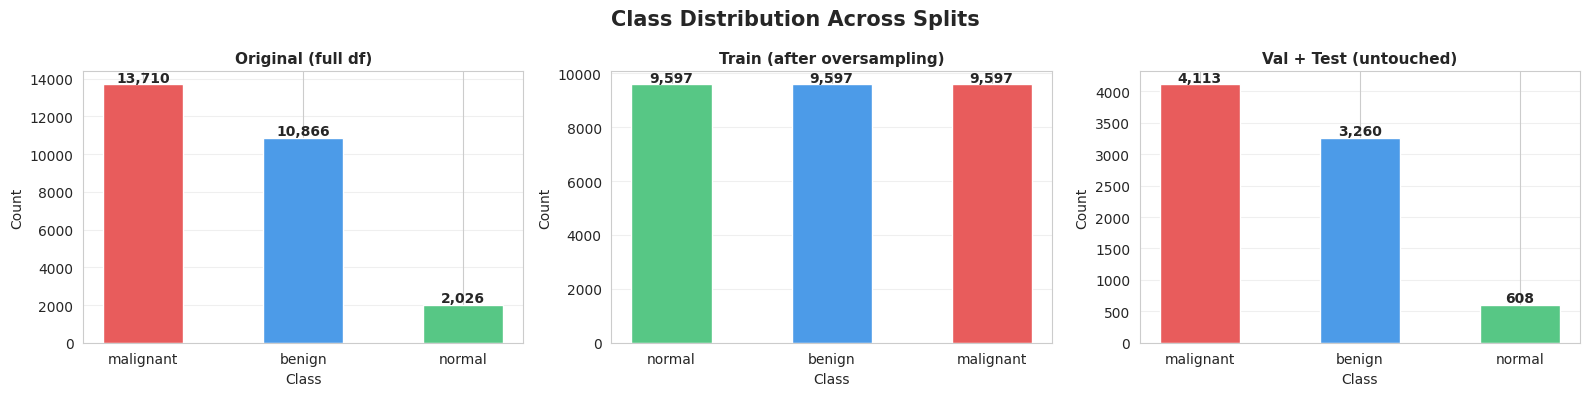

In [24]:
# ── Distribution Plot ──────────────────────────────────────────────────────
palette = {'benign': '#4C9BE8', 'malignant': '#E85C5C', 'normal': '#57C785'}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle('Class Distribution Across Splits', fontsize=15,
fontweight='bold')

for ax, (title, data) in zip(axes, [
    ('Original (full df)',         df),
    ('Train (after oversampling)', train_df_balanced),
    ('Val + Test (untouched)',      pd.concat([val_df, test_df]))
]):
    counts = data['label'].value_counts()
    bars   = ax.bar(counts.index, counts.values,
                    color=[palette[l] for l in counts.index],
edgecolor='white', width=0.5)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('Class'); ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=0)
    ax.grid(axis='y', alpha=0.3)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + max(counts)*0.01,
                f'{int(bar.get_height()):,}', ha='center', fontsize=10,
fontweight='bold')

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [25]:
IMG_SIZE   = 224
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.3),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])


class MammographyDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df        = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        image = Image.open(row['image_path']).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, int(row['label_idx'])


train_dataset = MammographyDataset(train_df_balanced,
transform=train_transform)
val_dataset   = MammographyDataset(val_df,
transform=val_transform)
test_dataset  = MammographyDataset(test_df,
transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True, drop_last=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE,
shuffle=False,
                          num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE,
shuffle=False,
                          num_workers=2, pin_memory=True)

print(f'Batches — Train: {len(train_loader)} | Val: {len(val_loader)} | Test: {len(test_loader)}')

Batches — Train: 899 | Val: 125 | Test: 125


In [28]:
import math
import time
import torch
import torch.nn as nn
import torch.nn.functional as F

class SurrogateSpike(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, alpha):
        ctx.save_for_backward(x)
        ctx.alpha = alpha
        return (x >= 0).float()

    @staticmethod
    def backward(ctx, grad_output):
        x, = ctx.saved_tensors
        alpha = ctx.alpha
        sg = torch.sigmoid(alpha * x)
        grad = alpha * sg * (1 - sg)
        return grad_output * grad, None

spike_fn = SurrogateSpike.apply

class LIFNode(nn.Module):
    def __init__(self, tau=2.0, v_th=1.0):
        super().__init__()
        self.tau = tau
        self.v_th = v_th
        self.alpha = 4.0
        self.v = 0.0

    def reset(self):
        self.v = 0.0

    def forward(self, x):
        self.v = self.v + (x - self.v) / self.tau
        spike = spike_fn(self.v - self.v_th, self.alpha)
        self.v = self.v * (1.0 - spike.detach())
        return spike

class SpikingPatchEmbed(nn.Module):
    def __init__(self, in_ch, embed_dim, img_size):
        super().__init__()
        c1, c2 = embed_dim // 4, embed_dim // 2
        self.proj1 = nn.Conv2d(in_ch, c1, 3, 2, 1)
        self.bn1 = nn.BatchNorm2d(c1)
        self.lif1 = LIFNode()

        self.proj2 = nn.Conv2d(c1, c2, 3, 2, 1)
        self.bn2 = nn.BatchNorm2d(c2)
        self.lif2 = LIFNode()

        self.proj3 = nn.Conv2d(c2, embed_dim, 3, 2, 1)
        self.bn3 = nn.BatchNorm2d(embed_dim)
        self.lif3 = LIFNode()

        self.proj4 = nn.Conv2d(embed_dim, embed_dim, 3, 2, 1)
        self.bn4 = nn.BatchNorm2d(embed_dim)
        self.lif4 = LIFNode()

    def forward(self, x):
        x = self.lif1(self.bn1(self.proj1(x)))
        x = self.lif2(self.bn2(self.proj2(x)))
        x = self.lif3(self.bn3(self.proj3(x)))
        x = self.lif4(self.bn4(self.proj4(x)))
        B, C, H, W = x.shape
        x = x.flatten(2).transpose(1, 2)
        return x

class SSA(nn.Module):
    def __init__(self, dim, heads):
        super().__init__()
        self.heads = heads
        self.scale = 0.125
        self.q_linear = nn.Linear(dim, dim)
        self.q_bn = nn.BatchNorm1d(dim)
        self.q_lif = LIFNode()

        self.k_linear = nn.Linear(dim, dim)
        self.k_bn = nn.BatchNorm1d(dim)
        self.k_lif = LIFNode()

        self.v_linear = nn.Linear(dim, dim)
        self.v_bn = nn.BatchNorm1d(dim)
        self.v_lif = LIFNode()

        self.attn_bn = nn.BatchNorm1d(dim)
        self.attn_lif = LIFNode()

        self.proj_linear = nn.Linear(dim, dim)
        self.proj_bn = nn.BatchNorm1d(dim)
        self.proj_lif = LIFNode()
        self.alpha = 4.0
        self.last_attn = None

    def set_alpha(self, a):
        self.alpha = a
        for m in [self.q_lif, self.k_lif, self.v_lif, self.attn_lif, self.proj_lif]:
            m.alpha = a

    def forward(self, x):
        B, N, C = x.shape
        H, d = self.heads, C // self.heads
        q = self.q_lif(self.q_bn(self.q_linear(x).transpose(1, 2)).transpose(1, 2))
        k = self.k_lif(self.k_bn(self.k_linear(x).transpose(1, 2)).transpose(1, 2))
        v = self.v_lif(self.v_bn(self.v_linear(x).transpose(1, 2)).transpose(1, 2))
        q = q.reshape(B, N, H, d).permute(0, 2, 1, 3)
        k = k.reshape(B, N, H, d).permute(0, 2, 1, 3)
        v = v.reshape(B, N, H, d).permute(0, 2, 1, 3)
        attn_raw = (q @ k.transpose(-2, -1)) * self.scale
        self.last_attn = attn_raw.detach()
        out = attn_raw @ v
        out = out.transpose(1, 2).reshape(B, N, C)
        out = self.attn_bn(out.transpose(1, 2)).transpose(1, 2)
        out = self.attn_lif(out)
        out = self.proj_lif(self.proj_bn(self.proj_linear(out).transpose(1, 2)).transpose(1, 2))
        return out

class SpikingMLP(nn.Module):
    def __init__(self, dim, ratio=4):
        super().__init__()
        hidden = dim * ratio
        self.fc1 = nn.Linear(dim, hidden)
        self.bn1 = nn.BatchNorm1d(hidden)
        self.lif1 = LIFNode()
        self.fc2 = nn.Linear(hidden, dim)
        self.bn2 = nn.BatchNorm1d(dim)
        self.lif2 = LIFNode()

    def set_alpha(self, a):
        self.lif1.alpha = a
        self.lif2.alpha = a

    def forward(self, x):
        x = self.lif1(self.bn1(self.fc1(x).transpose(1, 2)).transpose(1, 2))
        x = self.lif2(self.bn2(self.fc2(x).transpose(1, 2)).transpose(1, 2))
        return x

class SpikeBlock(nn.Module):
    def __init__(self, dim, heads):
        super().__init__()
        self.ssa = SSA(dim, heads)
        self.mlp = SpikingMLP(dim)

    def set_alpha(self, a):
        self.ssa.set_alpha(a)
        self.mlp.set_alpha(a)

    def forward(self, x):
        x = x + self.ssa(x)
        x = x + self.mlp(x)
        return x

class SAGESpikformer(nn.Module):
    def __init__(self, img_size, in_ch, embed_dim, depth, heads, num_classes, T):
        super().__init__()
        self.T = T
        self.depth = depth
        self.patch_embed = SpikingPatchEmbed(in_ch, embed_dim, img_size)
        self.blocks = nn.ModuleList([SpikeBlock(embed_dim, heads) for _ in range(depth)])
        self.head = nn.Linear(embed_dim, num_classes)

    def reset(self):
        for m in self.modules():
            if isinstance(m, LIFNode):
                m.reset()

    def set_block_alphas(self, alphas):
        for blk, a in zip(self.blocks, alphas):
            blk.set_alpha(a)

    def forward(self, x):
        self.reset()
        out_sum = 0.0
        attn_maps = [[] for _ in range(self.depth)]
        for t in range(self.T):
            feat = self.patch_embed(x)
            for i, blk in enumerate(self.blocks):
                feat = blk(feat)
                attn_maps[i].append(blk.ssa.last_attn)
            pooled = feat.mean(1)
            out_sum = out_sum + self.head(pooled)
        return out_sum / self.T, attn_maps

class SAGEController:
    def __init__(self, num_blocks, tau_e=0.25, beta=0.95, delta=0.25, alpha0=4.0, amin=3.0, amax=5.0, eps=1e-6):
        self.B = num_blocks
        self.tau_e = tau_e
        self.beta = beta
        self.delta = delta
        self.alpha0 = alpha0
        self.amin = amin
        self.amax = amax
        self.eps = eps
        self.m = [0.0] * num_blocks
        self.mu = [0.0] * num_blocks
        self.var = [1.0] * num_blocks
        self.count = 0
        self.alphas = [alpha0] * num_blocks
        self.history = [[] for _ in range(num_blocks)]

    def warmup_alphas(self):
        return [self.alpha0] * self.B

    def update(self, attn_maps_per_block):
        d_list = []
        for b in range(self.B):
            attn_t = torch.stack(attn_maps_per_block[b], dim=0)
            probs = F.softmax(attn_t / self.tau_e, dim=-1)
            N = probs.shape[-1]
            ent = -(probs * torch.log(probs + 1e-8)).sum(-1) / math.log(N)
            h = ent.mean(dim=(0, 1, 3))
            d_list.append(h.std().item())
        self.count += 1
        for b in range(self.B):
            self.m[b] = self.beta * self.m[b] + (1 - self.beta) * d_list[b]
            delta_ = self.m[b] - self.mu[b]
            self.mu[b] += delta_ / self.count
            self.var[b] += delta_ * (self.m[b] - self.mu[b])
        z = []
        for b in range(self.B):
            std = math.sqrt(max(self.var[b] / max(self.count, 1), 1e-8))
            z.append((self.m[b] - self.mu[b]) / (std + self.eps))
        zbar = sum(z) / self.B
        zc = [zi - zbar for zi in z]
        new_alphas = []
        for b in range(self.B):
            a = self.alpha0 if abs(zc[b]) < self.delta else self.alpha0 + 0.5 * math.tanh(zc[b])
            a = min(max(a, self.amin), self.amax)
            new_alphas.append(a)
            self.history[b].append(a)
        self.alphas = new_alphas
        return self.alphas

Epoch 1/5 [Val]: 100%|██████████| 125/125 [00:26<00:00,  4.71it/s]


Epoch 1: train_loss=0.7463 train_acc=0.6667 val_loss=0.7597 val_acc=0.6348 time=555.1s alphas=[4.0, 4.0, 4.0, 4.0]


Epoch 2/5 [Val]: 100%|██████████| 125/125 [00:26<00:00,  4.68it/s]


Epoch 2: train_loss=0.6618 train_acc=0.7338 val_loss=1.0242 val_acc=0.5035 time=558.7s alphas=[4.0, 4.0, 4.0, 4.0]


Epoch 3/5 [Val]: 100%|██████████| 125/125 [00:26<00:00,  4.67it/s]


Epoch 3: train_loss=0.5832 train_acc=0.8053 val_loss=0.8346 val_acc=0.6514 time=559.6s alphas=[4.0, 4.0, 4.0, 4.0]


... (2 outputs left out)

Epoch 5/5 [Val]: 100%|██████████| 125/125 [00:26<00:00,  4.67it/s]


Epoch 5: train_loss=0.5216 train_acc=0.8472 val_loss=0.5997 val_acc=0.7922 time=560.0s alphas=[4.0, 4.0, 4.0, 4.0]


Test: 100%|██████████| 125/125 [00:26<00:00,  4.66it/s]


Test Accuracy: 0.8038
              precision    recall  f1-score   support

      benign       0.77      0.81      0.79      1630
   malignant       0.84      0.77      0.81      2057
      normal       0.78      1.00      0.88       304

    accuracy                           0.80      3991
   macro avg       0.80      0.86      0.82      3991
weighted avg       0.81      0.80      0.80      3991



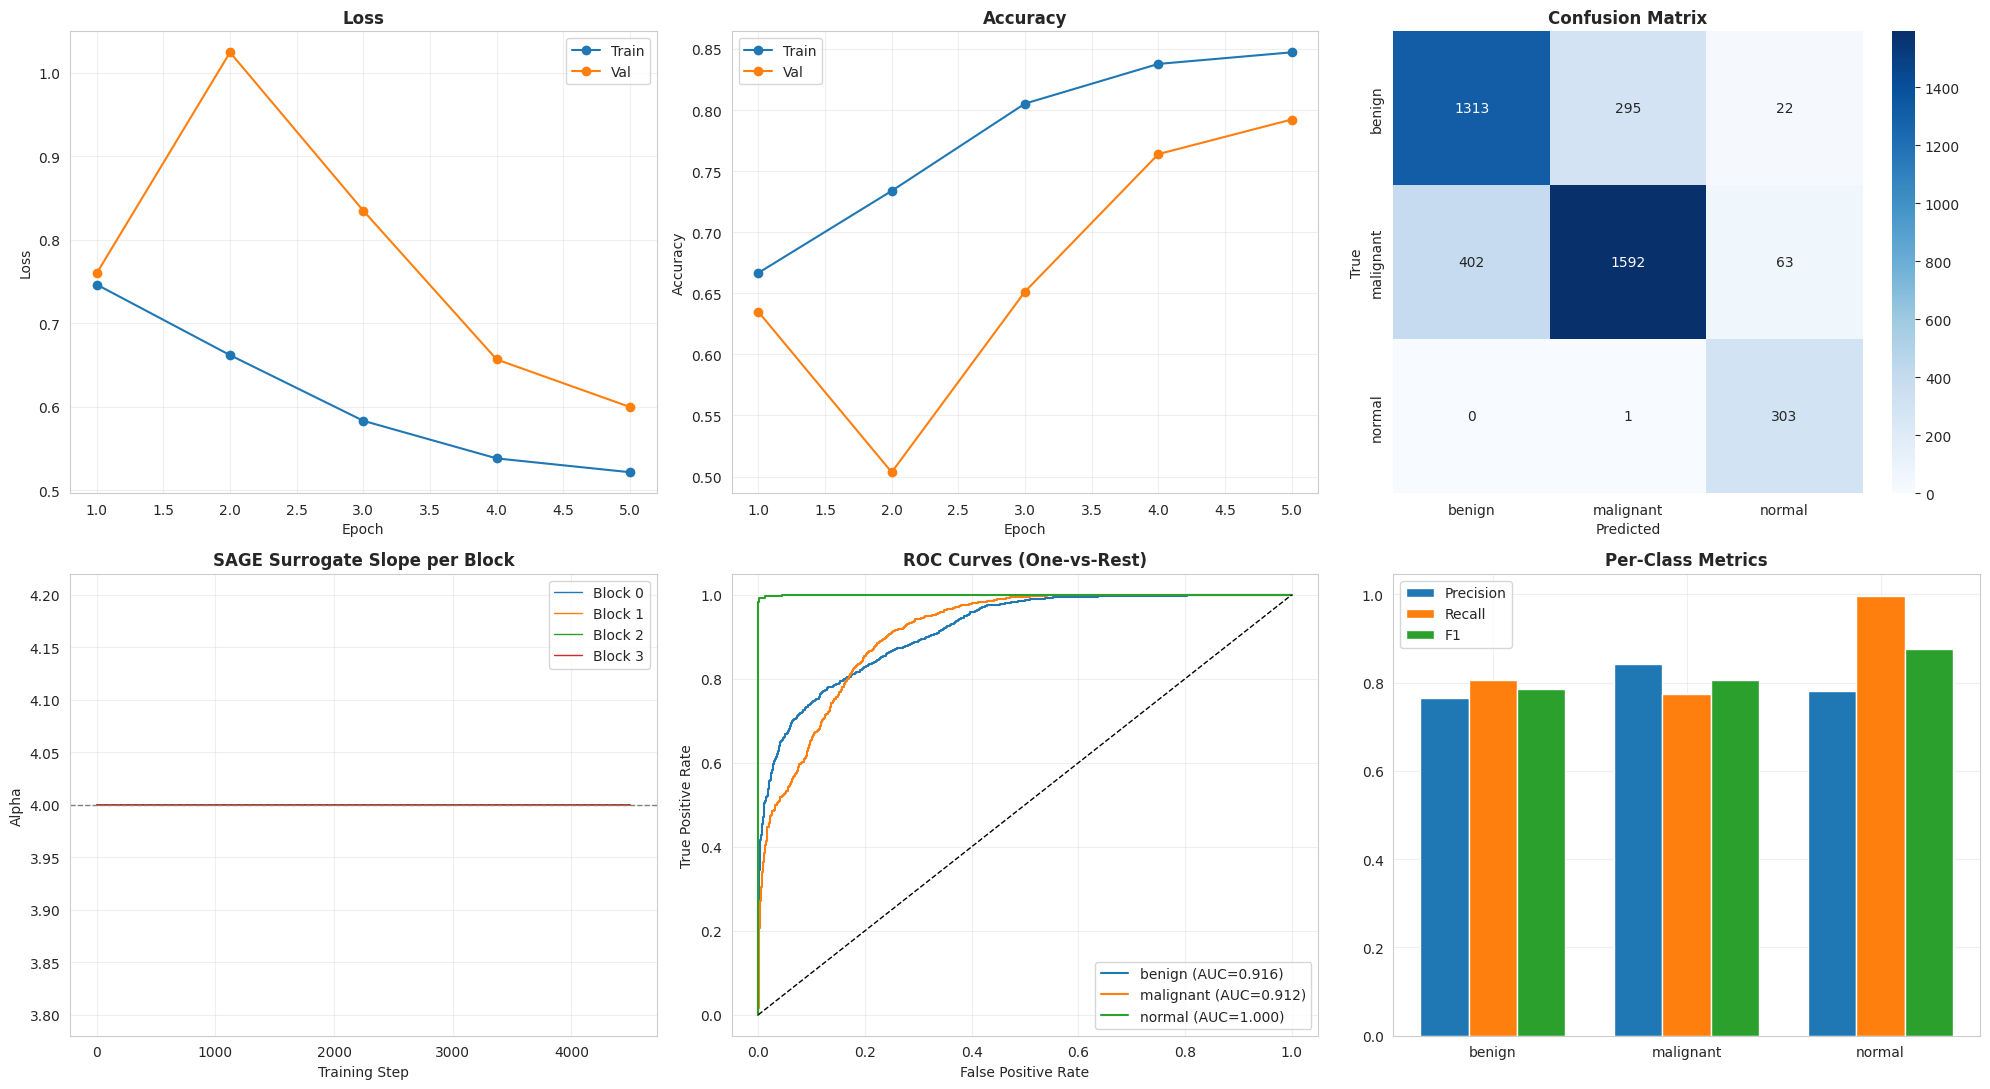

In [31]:
EPOCHS = 5
EMBED_DIM = 192
DEPTH = 4
HEADS = 6
T_STEPS = 4
LR = 3e-4

model = SAGESpikformer(
    img_size=IMG_SIZE,
    in_ch=3,
    embed_dim=EMBED_DIM,
    depth=DEPTH,
    heads=HEADS,
    num_classes=NUM_CLASSES,
    T=T_STEPS
).to(DEVICE)

controller = SAGEController(num_blocks=DEPTH)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=0.05)
total_steps = EPOCHS * len(train_loader)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=total_steps)
warmup_steps = len(train_loader)

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'epoch_time': []}
global_step = 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss, running_correct, running_total = 0.0, 0, 0
    t0 = time.time()
    pbar = tqdm(train_loader, desc=f'Epoch {epoch}/{EPOCHS} [Train]')
    for imgs, labels in pbar:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        current_alphas = controller.warmup_alphas() if global_step < warmup_steps else controller.alphas
        model.set_block_alphas(current_alphas)
        optimizer.zero_grad()
        logits, attn_maps = model(imgs)
        loss = criterion(logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        optimizer.step()
        scheduler.step()
        with torch.no_grad():
            controller.update(attn_maps)
        preds = logits.argmax(1)
        running_correct += (preds == labels).sum().item()
        running_total += labels.size(0)
        running_loss += loss.item() * labels.size(0)
        global_step += 1
        pbar.set_postfix(
            loss=f'{running_loss/running_total:.4f}',
            acc=f'{running_correct/running_total:.4f}',
            alpha=[round(a, 2) for a in controller.alphas]
        )
    train_loss = running_loss / running_total
    train_acc = running_correct / running_total
    epoch_time = time.time() - t0

    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in tqdm(val_loader, desc=f'Epoch {epoch}/{EPOCHS} [Val]'):
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            model.set_block_alphas(controller.alphas)
            logits, _ = model(imgs)
            loss = criterion(logits, labels)
            val_loss += loss.item() * labels.size(0)
            val_correct += (logits.argmax(1) == labels).sum().item()
            val_total += labels.size(0)
    val_loss /= val_total
    val_acc = val_correct / val_total

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['epoch_time'].append(epoch_time)
    print(f'Epoch {epoch}: train_loss={train_loss:.4f} train_acc={train_acc:.4f} val_loss={val_loss:.4f} val_acc={val_acc:.4f} time={epoch_time:.1f}s alphas={[round(a,2) for a in controller.alphas]}')

model.eval()
all_preds, all_labels, all_probs = [], [], []
with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc='Test'):
        imgs = imgs.to(DEVICE)
        model.set_block_alphas(controller.alphas)
        logits, _ = model(imgs)
        probs = F.softmax(logits, dim=1).cpu().numpy()
        all_preds.extend(probs.argmax(1))
        all_labels.extend(labels.numpy())
        all_probs.extend(probs)

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
all_probs = np.array(all_probs)
test_acc = accuracy_score(all_labels, all_preds)
print(f'Test Accuracy: {test_acc:.4f}')
print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES))

fig, axes = plt.subplots(2, 3, figsize=(20, 11))

axes[0, 0].plot(range(1, EPOCHS + 1), history['train_loss'], marker='o', label='Train')
axes[0, 0].plot(range(1, EPOCHS + 1), history['val_loss'], marker='o', label='Val')
axes[0, 0].set_title('Loss', fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

axes[0, 1].plot(range(1, EPOCHS + 1), history['train_acc'], marker='o', label='Train')
axes[0, 1].plot(range(1, EPOCHS + 1), history['val_acc'], marker='o', label='Val')
axes[0, 1].set_title('Accuracy', fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0, 2])
axes[0, 2].set_title('Confusion Matrix', fontweight='bold')
axes[0, 2].set_xlabel('Predicted')
axes[0, 2].set_ylabel('True')

for b in range(DEPTH):
    axes[1, 0].plot(controller.history[b], label=f'Block {b}', linewidth=1)
axes[1, 0].axhline(4.0, color='gray', linestyle='--', linewidth=1)
axes[1, 0].set_title('SAGE Surrogate Slope per Block', fontweight='bold')
axes[1, 0].set_xlabel('Training Step')
axes[1, 0].set_ylabel('Alpha')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

y_bin = label_binarize(all_labels, classes=list(range(NUM_CLASSES)))
for i, c in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_bin[:, i], all_probs[:, i])
    roc_auc = auc(fpr, tpr)
    axes[1, 1].plot(fpr, tpr, label=f'{c} (AUC={roc_auc:.3f})')
axes[1, 1].plot([0, 1], [0, 1], 'k--', linewidth=1)
axes[1, 1].set_title('ROC Curves (One-vs-Rest)', fontweight='bold')
axes[1, 1].set_xlabel('False Positive Rate')
axes[1, 1].set_ylabel('True Positive Rate')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

prec = precision_score(all_labels, all_preds, average=None)
rec = recall_score(all_labels, all_preds, average=None)
f1 = f1_score(all_labels, all_preds, average=None)
x = np.arange(NUM_CLASSES)
width = 0.25
axes[1, 2].bar(x - width, prec, width, label='Precision')
axes[1, 2].bar(x, rec, width, label='Recall')
axes[1, 2].bar(x + width, f1, width, label='F1')
axes[1, 2].set_xticks(x)
axes[1, 2].set_xticklabels(CLASS_NAMES)
axes[1, 2].set_title('Per-Class Metrics', fontweight='bold')
axes[1, 2].legend()
axes[1, 2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('sage_training_results.png', dpi=150, bbox_inches='tight')
plt.show()